## Assignment no 7

## Multiple Linear Regression — Toyota Corolla Price Prediction

Assignment Task:

Your task is to perform a multiple linear regression analysis to predict the price of Toyota corolla based on the given attributes.

Dataset Description:

The dataset consists of the following variables:

Age: Age in years

KM: Accumulated Kilometers on odometer

FuelType: Fuel Type (Petrol, Diesel, CNG)

HP: Horse Power

Automatic: Automatic ( (Yes=1, No=0)

CC: Cylinder Volume in cubic centimeters

Doors: Number of doors

Weight: Weight in Kilograms

Quarterly_Tax: 


Price: Offer Price in EUROs


In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

1. LOAD DATASET

In [36]:
df = pd.read_csv("ToyotaCorolla.csv")

df.columns = df.columns.str.strip()

df.head()

df.shape


df.info()


df.isnull().sum()

df.duplicated().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1436 entries, 0 to 1435
Data columns (total 11 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Price      1436 non-null   int64 
 1   Age_08_04  1436 non-null   int64 
 2   KM         1436 non-null   int64 
 3   Fuel_Type  1436 non-null   object
 4   HP         1436 non-null   int64 
 5   Automatic  1436 non-null   int64 
 6   cc         1436 non-null   int64 
 7   Doors      1436 non-null   int64 
 8   Cylinders  1436 non-null   int64 
 9   Gears      1436 non-null   int64 
 10  Weight     1436 non-null   int64 
dtypes: int64(10), object(1)
memory usage: 123.5+ KB


1

In [37]:
#Select assignment columns that exist in the dataset
features = [
    "Age", "KM", "FuelType", "HP", "Automatic",
    "CC", "Doors", "Weight", "Quarterly_Tax"
]

target = "Price"

if target not in df.columns:
    raise ValueError("The dataset must contain a 'Price' column.")

features = [col for col in features if col in df.columns]

df = df[features + [target]].copy()
df[target] = pd.to_numeric(df[target], errors="coerce")
df = df.dropna(subset=[target]).drop_duplicates()

X = df[features]
y = df[target]

# ============================================================
# 2. EXPLORATORY DATA ANALYSIS (EDA)
# ============================================================


Summary statistics:
                  KM           HP    Automatic        Doors       Weight  \
count    1431.000000  1431.000000  1431.000000  1431.000000  1431.000000   
mean    68676.105521   101.494060     0.055905     4.032844  1072.356394   
std     37474.531997    14.992905     0.229818     0.952529    52.287881   
min         1.000000    69.000000     0.000000     2.000000  1000.000000   
25%     43000.000000    90.000000     0.000000     3.000000  1040.000000   
50%     63500.000000   110.000000     0.000000     4.000000  1070.000000   
75%     87178.500000   110.000000     0.000000     5.000000  1085.000000   
max    243000.000000   192.000000     1.000000     5.000000  1615.000000   

              Price  
count   1431.000000  
mean   10717.273934  
std     3607.538907  
min     4350.000000  
25%     8450.000000  
50%     9900.000000  
75%    11950.000000  
max    32500.000000  


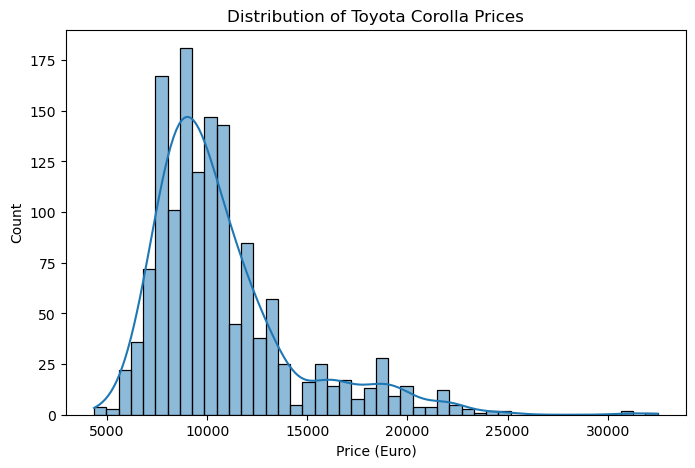

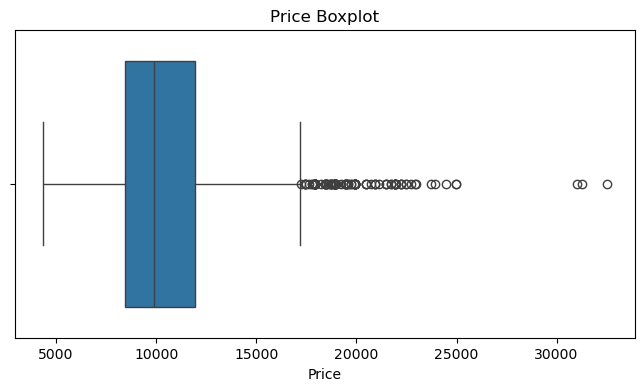

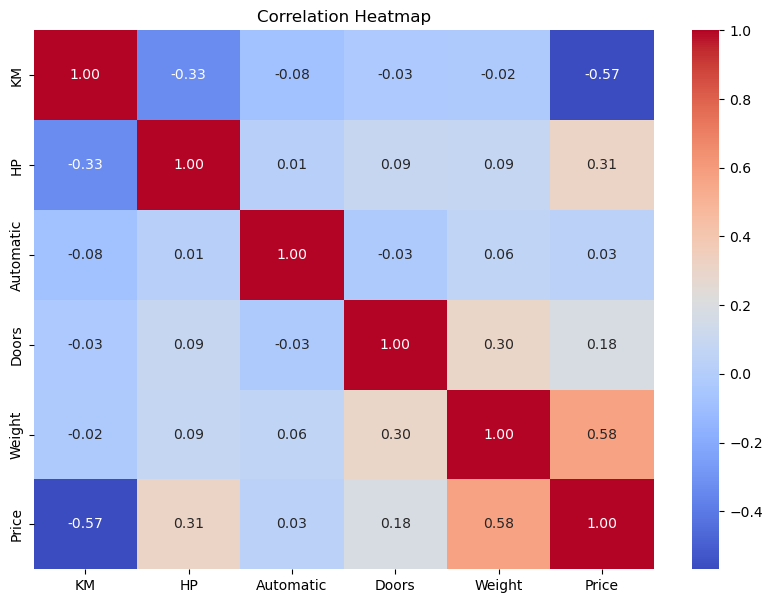

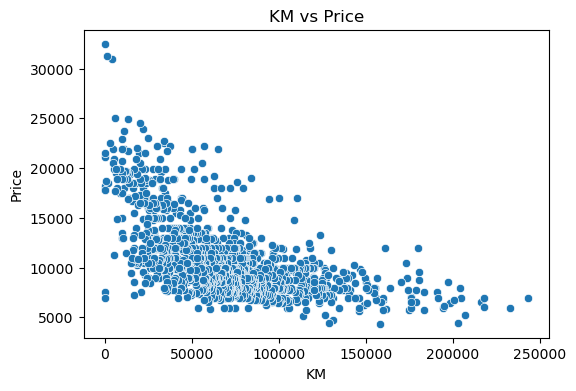

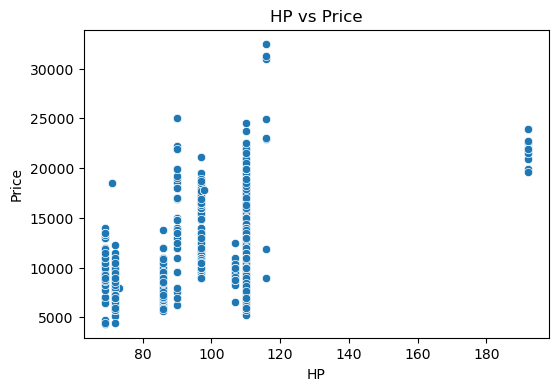

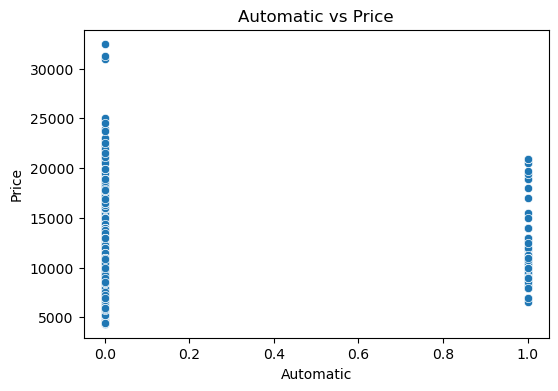

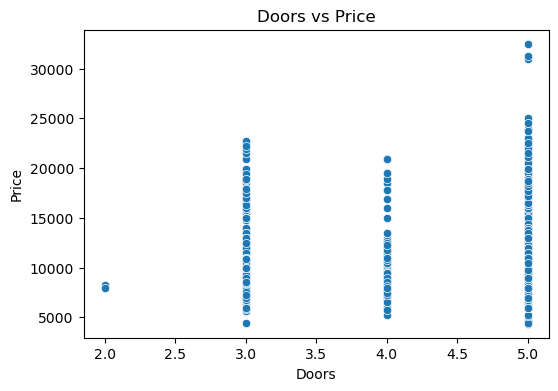

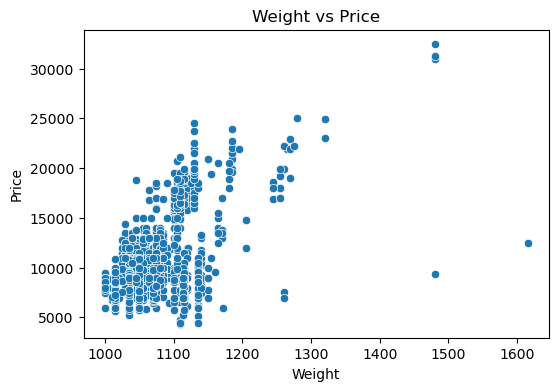

In [38]:
print("\nSummary statistics:")
print(df.describe(include="all"))

# Price distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["Price"], kde=True)
plt.title("Distribution of Toyota Corolla Prices")
plt.xlabel("Price (Euro)")
plt.show()

# Price outliers
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["Price"])
plt.title("Price Boxplot")
plt.show()

# Correlation heatmap for numerical variables
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.show()

# Scatterplots for numerical predictors
for col in numeric_df.columns:
    if col != "Price":
        plt.figure(figsize=(6, 4))
        sns.scatterplot(data=df, x=col, y="Price")
        plt.title(f"{col} vs Price")
        plt.show()

# Compare prices across fuel types
if "FuelType" in df.columns:
    plt.figure(figsize=(7, 5))
    sns.boxplot(data=df, x="FuelType", y="Price")
    plt.title("Price by Fuel Type")
    plt.show()


# ============================================================
# 3. PREPROCESSING
# ============================================================


In [39]:
# Identify categorical and numerical columns
categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_features = [
    col for col in X.columns
    if col not in categorical_features
]

# Automatic is normally coded as 0/1
if "Automatic" in X.columns:
    converted = pd.to_numeric(X["Automatic"], errors="coerce")
    if converted.notna().any():
        X = X.copy()
        X["Automatic"] = converted

        if "Automatic" in categorical_features:
            categorical_features.remove("Automatic")

        if "Automatic" not in numeric_features:
            numeric_features.append("Automatic")

# Numerical preprocessing: fill missing values and standardize
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing: fill missing values and encode categories
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

transformers = []

if numeric_features:
    transformers.append(
        ("num", numeric_transformer, numeric_features)
    )

if categorical_features:
    transformers.append(
        ("cat", categorical_transformer, categorical_features)
    )

preprocessor = ColumnTransformer(transformers=transformers)


# ============================================================
# 4. TRAIN-TEST SPLIT
# ============================================================

In [40]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))



Training samples: 1144
Testing samples: 287


# ============================================================
# 5. BUILD THREE REGRESSION MODELS
# ============================================================



In [41]:
models = {
    "Multiple Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.1, max_iter=20000)
}

results = []
fitted_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    # Train model
    pipeline.fit(X_train, y_train)

    # Predict test prices
    y_pred = pipeline.predict(X_test)

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

    fitted_models[name] = pipeline

# ============================================================
# 6. MODEL EVALUATION
# ============================================================



Model Performance Comparison:
                     Model      MAE         MSE     RMSE  R2 Score
Multiple Linear Regression 1614.207 4625978.898 2150.809     0.601
          Ridge Regression 1614.357 4624743.391 2150.522     0.601
          Lasso Regression 1614.222 4625945.485 2150.801     0.601

Best model based on test RMSE: Ridge Regression


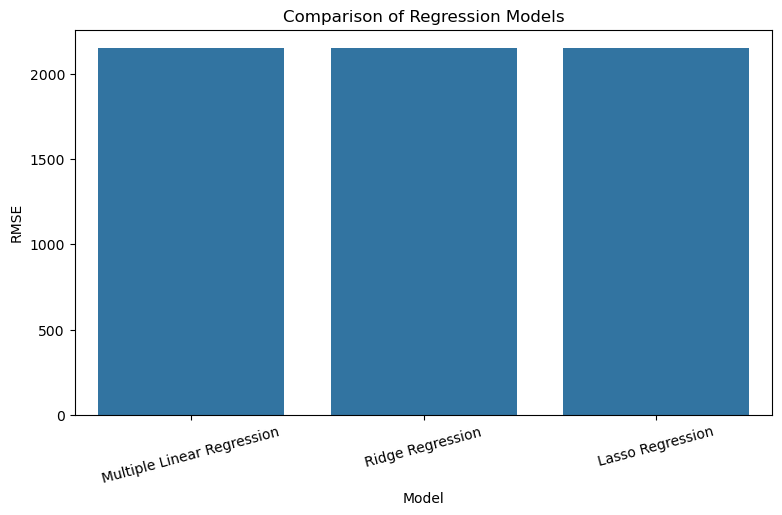

In [42]:
results_df = pd.DataFrame(results)

print("\nModel Performance Comparison:")
print(results_df.round(3).to_string(index=False))

# Select model with lowest RMSE
best_index = results_df["RMSE"].idxmin()
best_model_name = results_df.loc[best_index, "Model"]
best_model = fitted_models[best_model_name]

print("\nBest model based on test RMSE:", best_model_name)

# Plot RMSE comparison
plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x="Model", y="RMSE")
plt.title("Comparison of Regression Models")
plt.xticks(rotation=15)
plt.show()


# ============================================================
# 7. INTERPRET LINEAR REGRESSION COEFFICIENTS
# ============================================================


In [43]:
linear_pipeline = fitted_models["Multiple Linear Regression"]

trained_preprocessor = linear_pipeline.named_steps["preprocessor"]
linear_model = linear_pipeline.named_steps["model"]

feature_names = trained_preprocessor.get_feature_names_out()

coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": linear_model.coef_
})

coefficients["Absolute Coefficient"] = (
    coefficients["Coefficient"].abs()
)

coefficients = coefficients.sort_values(
    by="Absolute Coefficient",
    ascending=False
)

print("\nLinear Regression Intercept:")
print(round(float(linear_model.intercept_), 3))

print("\nRegression Coefficients:")
print(coefficients.to_string(index=False))

# Note:
# Numeric predictors were standardized. Their coefficients represent
# the estimated price change for a one-standard-deviation increase,
# holding other predictors constant.
#
# FuelType coefficients compare encoded categories with the reference
# category, holding other predictors constant.



Linear Regression Intercept:
10769.055

Regression Coefficients:
       Feature  Coefficient  Absolute Coefficient
   num__Weight  2084.397921           2084.397921
       num__KM -1919.926623           1919.926623
       num__HP   319.020316            319.020316
num__Automatic  -120.275286            120.275286
    num__Doors   -67.196301             67.196301


# ============================================================
# 8. ACTUAL VS PREDICTED PRICES
# ============================================================


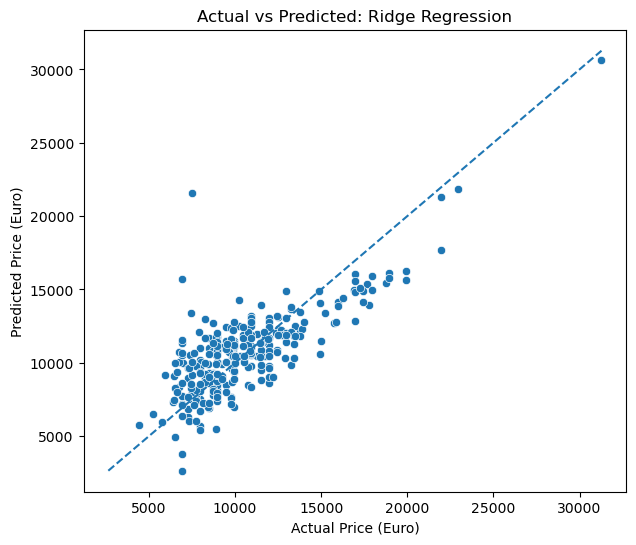

In [44]:
y_pred_best = best_model.predict(X_test)

plt.figure(figsize=(7, 6))
sns.scatterplot(x=y_test, y=y_pred_best)

minimum = min(y_test.min(), y_pred_best.min())
maximum = max(y_test.max(), y_pred_best.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual Price (Euro)")
plt.ylabel("Predicted Price (Euro)")
plt.title(f"Actual vs Predicted: {best_model_name}")
plt.show()


# ============================================================
# 9. RESIDUAL ANALYSIS
# ============================================================



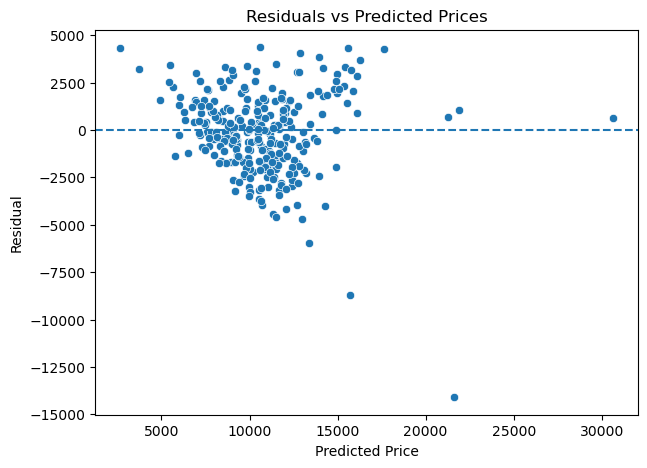

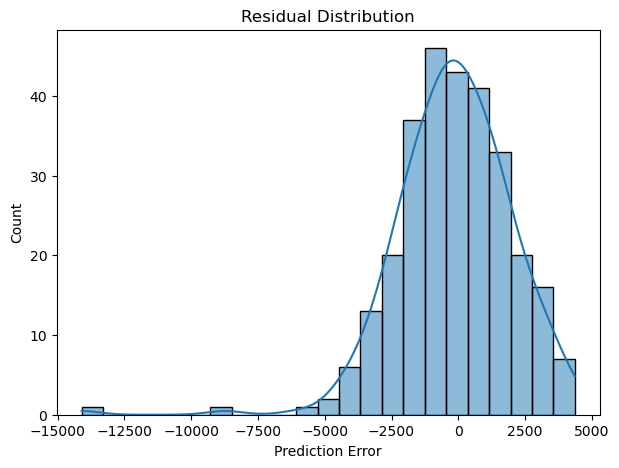

In [45]:
residuals = y_test - y_pred_best

plt.figure(figsize=(7, 5))
sns.scatterplot(x=y_pred_best, y=residuals)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted Price")
plt.ylabel("Residual")
plt.title("Residuals vs Predicted Prices")
plt.show()

plt.figure(figsize=(7, 5))
sns.histplot(residuals, kde=True)
plt.title("Residual Distribution")
plt.xlabel("Prediction Error")
plt.show()


# ============================================================
# 10. SAMPLE PRICE PREDICTION
# ============================================================


In [46]:
sample = X_test.iloc[[0]]

actual_price = y_test.iloc[0]
predicted_price = best_model.predict(sample)[0]

print("\nSample Input:")
print(sample.to_string(index=False))

print(f"\nActual Price: EUR {actual_price:.2f}")
print(f"Predicted Price: EUR {predicted_price:.2f}")
print(
    f"Absolute Error: EUR "
    f"{abs(actual_price - predicted_price):.2f}"
)



Sample Input:
   KM  HP  Automatic  Doors  Weight
36012 110          0      5    1130

Actual Price: EUR 16950.00
Predicted Price: EUR 14864.48
Absolute Error: EUR 2085.52


# ============================================================
# 11. FINAL CONCLUSION
# ============================================================


In [47]:
print("\n========== FINAL CONCLUSION ==========")
print("Dataset rows used:", len(df))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Best model:", best_model_name)

best_metrics = results_df.loc[best_index]

print(f"MAE: {best_metrics['MAE']:.2f}")
print(f"RMSE: {best_metrics['RMSE']:.2f}")
print(f"R2 Score: {best_metrics['R2 Score']:.4f}")

print("\nInterpretation:")
print("- MAE and RMSE measure prediction error in Euros.")
print("- Lower MAE and RMSE indicate smaller prediction errors.")
print("- R2 measures how much variation in Price is explained by the model.")
print("- Ridge penalizes large coefficients to reduce overfitting.")
print("- Lasso can shrink some coefficients to zero.")

print("\nAssumptions:")
print("1. Predictors have an approximately linear relationship with Price.")
print("2. Observations and errors are independent.")
print("3. Residual variance is approximately constant.")
print("4. Severe multicollinearity should be checked.")
print("5. Test-set results are estimates of performance on unseen data.")
print("6. Actual results depend on the supplied dataset.")


========== FINAL CONCLUSION ==========
Dataset rows used: 1431
Training samples: 1144
Testing samples: 287
Best model: Ridge Regression
MAE: 1614.36
RMSE: 2150.52
R2 Score: 0.6009

Interpretation:
- MAE and RMSE measure prediction error in Euros.
- Lower MAE and RMSE indicate smaller prediction errors.
- R2 measures how much variation in Price is explained by the model.
- Ridge penalizes large coefficients to reduce overfitting.
- Lasso can shrink some coefficients to zero.

Assumptions:
1. Predictors have an approximately linear relationship with Price.
2. Observations and errors are independent.
3. Residual variance is approximately constant.
4. Severe multicollinearity should be checked.
5. Test-set results are estimates of performance on unseen data.
6. Actual results depend on the supplied dataset.
